<a href="https://colab.research.google.com/github/svend4/infod10/blob/main/_untitled3_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 🛠️ Интерактивные шаблоны для тестирования возможностей

Ниже представлены три готовых шаблона для самых популярных задач. Просто выберите нужный блок и запустите его.

#### 📊 Шаблон №1: Анализ данных и визуализация (EDA)
Запустите этот код, чтобы сгенерировать синтетические данные о продажах и построить графики.

--- Первые 5 строк датасета ---


,Дата,Продажи_USD,Количество_клиентов,Рейтинг_удовлетворенности
0,2023-01-01,549.67,28,3.9
1,2023-01-02,486.17,56,4.5
2,2023-01-03,564.77,52,4.7
3,2023-01-04,652.30,70,4.3
4,2023-01-05,476.58,61,4.3



--- Описание данных ---


,Дата,Продажи_USD,Количество_клиентов,Рейтинг_удовлетворенности
count,100,100.000000,100.000000,100.000000
mean,2023-02-19 12:00:00,489.615300,50.450000,4.327000
min,2023-01-01 00:00:00,238.030000,20.000000,3.500000
25%,2023-01-25 18:00:00,439.912500,36.000000,3.975000
50%,2023-02-19 12:00:00,487.305000,51.000000,4.400000
75%,2023-03-16 06:00:00,540.595000,68.000000,4.700000
max,2023-04-10 00:00:00,685.230000,79.000000,5.000000
std,NaN,90.816089,18.244897,0.434347


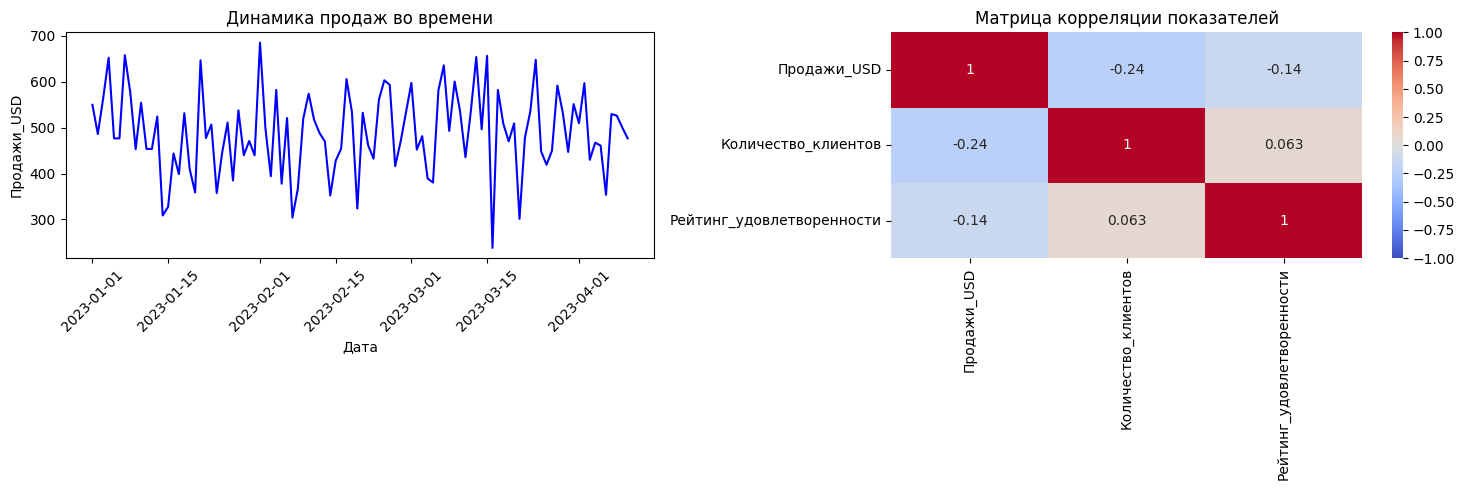

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Создаем случайные данные продаж
np.random.seed(42)
dates = pd.date_range(start="2023-01-01", periods=100)
data = {
    'Дата': dates,
    'Продажи_USD': np.random.normal(loc=500, scale=100, size=100).round(2),
    'Количество_клиентов': np.random.randint(20, 80, size=100),
    'Рейтинг_удовлетворенности': np.random.uniform(3.5, 5.0, size=100).round(1)
}
df = pd.DataFrame(data)

# 2. Выводим базовую статистику
print("--- Первые 5 строк датасета ---")
display(df.head())

print("\n--- Описание данных ---")
display(df.describe())

# 3. Строим графики
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График динамики продаж
sns.lineplot(ax=axes[0], x='Дата', y='Продажи_USD', data=df, color='blue')
axes[0].set_title('Динамика продаж во времени')
axes[0].tick_params(axis='x', rotation=45)

# Корреляция между метриками
sns.heatmap(ax=axes[1], data=df[['Продажи_USD', 'Количество_клиентов', 'Рейтинг_удовлетворенности']].corr(),
            annot=True, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_title('Матрица корреляции показателей')

plt.tight_layout()
plt.show()

#### 🤖 Шаблон №2: Машинное обучение (Обучение классификатора)
Этот шаблон создает искусственную задачу классификации (например, уйдет клиент или нет) и обучает модель Random Forest.

Отчет о классификации (Classification Report):
              precision    recall  f1-score   support

           0       0.94      0.92      0.93        51
           1       0.92      0.94      0.93        49

    accuracy                           0.93       100
   macro avg       0.93      0.93      0.93       100
weighted avg       0.93      0.93      0.93       100



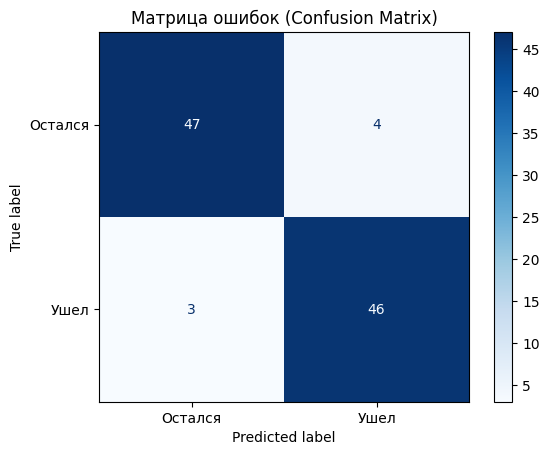

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Генерируем данные для классификации
X, y = make_classification(n_samples=500, n_features=5, n_informative=3, n_classes=2, random_state=42)

# 2. Разделяем на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Обучаем модель
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 4. Делаем предсказание и оцениваем качество
y_pred = model.predict(X_test)

print("Отчет о классификации (Classification Report):")
print(classification_report(y_test, y_pred))

# Визуализируем Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Остался', 'Ушел'])
disp.plot(cmap='Blues')
plt.title('Матрица ошибок (Confusion Matrix)')
plt.show()

#### 🔗 Шаблон №3: Подключение к Gemini API
Используйте этот шаблон, если хотите интегрировать генеративный ИИ в ваш рабочий процесс.

In [ ]:
# Шаблон интеграции с Gemini API
# Примечание: Для работы этого кода требуется добавить ключ GOOGLE_API_KEY в Secrets (значок ключа слева)

try:
    from google import genai
    from google.colab import userdata

    # Получение ключа из секретов Colab
    GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
    client = genai.Client(api_key=GOOGLE_API_KEY)

    response = client.models.generate_content(
        model='gemini-2.5-flash-lite',
        contents='Напиши краткий план, как стать специалистом по Data Science в 2025 году.',
    )
    print("Ответ от Gemini:")
    print(response.text)
except Exception as e:
    print("Информация: Настройте API-ключ в панели секретов Colab (имя ключа: GOOGLE_API_KEY) для запуска этого шага.")
    print(f"Детали ошибки (если вы пытались запустить): {e}")

Информация: Настройте API-ключ в панели секретов Colab (имя ключа: GOOGLE_API_KEY) для запуска этого шага.
Детали ошибки (если вы пытались запустить): Secret GOOGLE_API_KEY does not exist.


### 🚀 Новые продвинутые шаблоны для тестирования

Ниже добавлены новые сценарии для интерактивного анализа, работы с реальными картами данных и кластеризацией.

#### 📈 Вариант 1: Интерактивная визуализация с Plotly
Попробуйте навести курсор на точки графика или приблизить отдельную область!

In [ ]:
import plotly.express as px

# Используем наш ранее созданный датасет df
fig = px.scatter(
    df,
    x="Количество_клиентов",
    y="Продажи_USD",
    size="Продажи_USD",
    color="Рейтинг_удовлетворенности",
    hover_name="Дата",
    title="Интерактивный анализ: Продажи vs Количество клиентов (размер = объем продаж)",
    color_continuous_scale=px.colors.sequential.Viridis
)

fig.show()

#### 🏠 Вариант 2: Анализ реальных данных (Цены на жилье в Калифорнии)
Используем встроенный в Colab датасет, чтобы визуализировать стоимость жилья на географической карте.

<Figure size 1000x700 with 0 Axes>

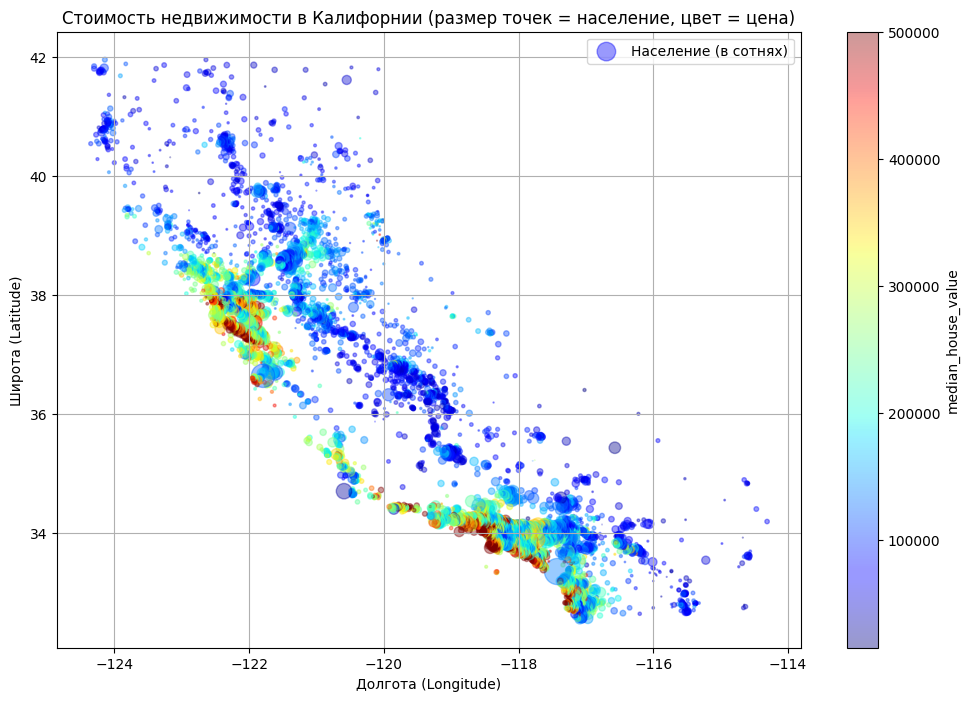

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем реальный датасет из файлов Colab
housing_df = pd.read_csv('/content/sample_data/california_housing_train.csv')

# Построим карту плотности стоимости жилья по координатам долготы и широты
plt.figure(figsize=(10, 7))
housing_df.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.4,
    s=housing_df["population"]/100,
    label="Население (в сотнях)",
    c="median_house_value",
    cmap=plt.get_cmap("jet"),
    colorbar=True,
    figsize=(12, 8)
)

plt.title("Стоимость недвижимости в Калифорнии (размер точек = население, цвет = цена)")
plt.xlabel("Долгота (Longitude)")
plt.ylabel("Широта (Latitude)")
plt.legend()
plt.grid(True)
plt.show()

#### 👥 Вариант 3: Сегментация клиентов (K-Means)
Разделение клиентов на группы по их поведению.

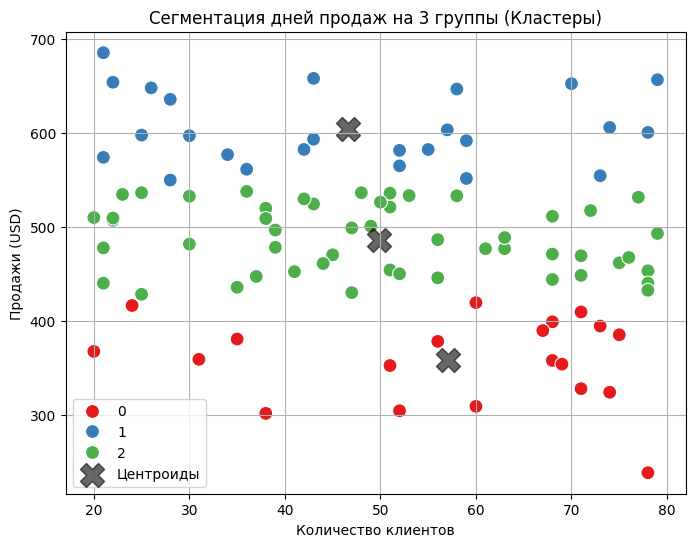

In [ ]:
from sklearn.cluster import KMeans
import seaborn as sns
import matplotlib.pyplot as plt

# Выбираем признаки для кластеризации
X_clust = df[['Количество_клиентов', 'Продажи_USD']]

# Обучаем K-Means для выделения 3 групп (кластеров)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Кластер'] = kmeans.fit_predict(X_clust)

# Визуализируем группы
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Количество_клиентов',
    y='Продажи_USD',
    hue='Кластер',
    palette='Set1',
    s=100
)

# Отметим центры кластеров
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=300, alpha=0.6, marker='X', label='Центроиды')

plt.title('Сегментация дней продаж на 3 группы (Кластеры)')
plt.xlabel('Количество клиентов')
plt.ylabel('Продажи (USD)')
plt.legend()
plt.grid(True)
plt.show()

### 🌸 Создание тестовых документов и веб-страниц

Ниже представлен код для генерации тестовых файлов в различных форматах (HTML для магазина цветов, JSON и CSV) для ваших тестов.

In [1]:
import os
import json
import pandas as pd

# Создаем папку для тестовых файлов
os.makedirs('/content/test_files', exist_ok=True)

# 1. HTML-страница: Главная страница магазина цветов
html_content = """<!DOCTYPE html>
<html lang='ru'>
<head>
    <meta charset='UTF-8'>
    <title>Цветочный Рай — Магазин Цветов</title>
    <style>
        body { font-family: Arial, sans-serif; background-color: #fdf6f6; color: #333; margin: 0; padding: 20px; }
        header { text-align: center; background-color: #ffb7b2; padding: 20px; color: white; border-radius: 8px; }
        .catalog { display: flex; justify-content: space-around; margin-top: 30px; flex-wrap: wrap; }
        .flower-card { background: white; border: 1px solid #ddd; border-radius: 8px; padding: 15px; width: 200px; text-align: center; box-shadow: 0 4px 6px rgba(0,0,0,0.1); margin: 10px; }
        .price { color: #e56b6f; font-weight: bold; font-size: 1.2em; }
        button { background-color: #e56b6f; color: white; border: none; padding: 10px 15px; border-radius: 5px; cursor: pointer; }
        button:hover { background-color: #b56576; }
    </style>
</head>
<body>
    <header>
        <h1>🌸 Цветочный Рай</h1>
        <p>Самые свежие букеты с доставкой</p>
    </header>
    <main>
        <h2 style='text-align: center;'>Наш Каталог</h2>
        <div class='catalog'>
            <div class='flower-card'>
                <h3>Букет "Нежность"</h3>
                <p>Розовые пионы и эвкалипт</p>
                <p class='price'>3 500 ₽</p>
                <button>В корзину</button>
            </div>
            <div class='flower-card'>
                <h3>Красные розы</h3>
                <p>Классический букет из 15 роз</p>
                <p class='price'>2 800 ₽</p>
                <button>В корзину</button>
            </div>
            <div class='flower-card'>
                <h3>Букет "Солнце"</h3>
                <p>Яркие подсолнухи и ромашки</p>
                <p class='price'>2 200 ₽</p>
                <button>В корзину</button>
            </div>
        </div>
    </main>
</body>
</html>
"""

with open('/content/test_files/flower_shop.html', 'w', encoding='utf-8') as f:
    f.write(html_content)

# 2. JSON-документ: Данные о заказах магазина
orders_data = [
    {"order_id": 101, "customer": "Анна", "items": [{"name": "Букет Нежность", "qty": 1, "price": 3500}], "status": "Доставлено"},
    {"order_id": 102, "customer": "Иван", "items": [{"name": "Красные розы", "qty": 2, "price": 2800}], "status": "В пути"},
    {"order_id": 103, "customer": "Мария", "items": [{"name": "Букет Солнце", "qty": 1, "price": 2200}], "status": "Новый"}
]

with open('/content/test_files/orders.json', 'w', encoding='utf-8') as f:
    json.dump(orders_data, f, ensure_ascii=False, indent=4)

# 3. CSV-документ: База поставщиков цветов
suppliers_df = pd.DataFrame({
    'ID': [1, 2, 3],
    'Название': ['Цветы Оптом', 'ЭкоФлора', 'Голландский Сад'],
    'Контакт': ['+7 999 111-22-33', '+7 999 444-55-66', '+7 999 777-88-99'],
    'Город': ['Москва', 'Краснодар', 'Санкт-Петербург']
})

suppliers_df.to_csv('/content/test_files/suppliers.csv', index=False, encoding='utf-8')

print("Тестовые файлы успешно созданы в папке '/content/test_files/':")
for file in os.listdir('/content/test_files'):
    print(f" - {file}")

Тестовые файлы успешно созданы в папке '/content/test_files/':
 - flower_shop.html
 - suppliers.csv
 - orders.json
